# PLN — Features de texto dos chamados

Cada chamado do dataset tem um **título** (`title`) e uma **descrição** (`description`). A etapa de **Processamento de Linguagem Natural (PLN)** lê esses dois textos e os transforma em **cinco colunas numéricas**, que depois são usadas pelo classificador multimodal junto com as imagens e os dados tabulares.

A ideia não é que o PLN descubra a categoria do chamado. Ele produz **sinais** sobre o texto: qual o tom do relato e que tipo de pedido ele parece ser. Cabe ao classificador final decidir se esses sinais ajudam.

O notebook está dividido em duas partes:

- **Parte 1 — O que é cada coluna:** o significado de cada uma, como interpretar os valores e o que elas mostram nos dados.
- **Parte 2 — Como as colunas foram geradas:** os modelos usados, o passo a passo do cálculo e onde isso está no código do projeto.

A célula abaixo só carrega o dataset gerado pela execução mais recente do pipeline.

In [1]:
from pathlib import Path
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXECUCAO = sorted(p.parent.name for p in (RAIZ / "reports" / "runs").glob("*/enriched.parquet")
                  if "text_failure_similarity" in pd.read_parquet(p).columns)[-1]
df = pd.read_parquet(RAIZ / "reports" / "runs" / EXECUCAO / "enriched.parquet")
COLUNAS = ["sentiment_score", "text_failure_similarity", "text_access_request_similarity",
           "text_guidance_similarity", "text_performance_similarity"]
print("Execução:", EXECUCAO, "| chamados:", len(df))

Execução: 20261031T011846_46cef21f | chamados: 5000


---
## Parte 1 — O que é cada coluna

### `sentiment_score` — o tom do relato

Mede se quem abriu o chamado escreveu de forma **negativa** (irritação, frustração), **neutra** ou **positiva** (agradecimento, satisfação).

- Vai de **−1** (muito negativo) a **+1** (muito positivo); **0** é neutro.
- O dataset original já tinha uma coluna com esse nome, mas o projeto decidiu **recalculá-la** para ter um valor confiável. Por isso ela **substitui** a original, em vez de ser uma coluna nova.
- Neste dataset, os valores ficam **quase todos perto de zero** (entre −0,22 e +0,12). Isso faz sentido: os chamados são frases curtas e objetivas, como "Falha no Excel: apresenta erro ao importar dados", sem emoção explícita.

### As quatro similaridades — que tipo de pedido o texto parece ser

As outras quatro colunas são **novas** e respondem à pergunta: *"o quanto este chamado se parece com um relato de…"*

| Coluna | … se parece com | Exemplo de frase que teria valor alto |
| --- | --- | --- |
| `text_failure_similarity` | uma **falha**: algo quebrado ou indisponível | "O sistema apresenta um erro e não funciona." |
| `text_access_request_similarity` | um **pedido de acesso**: conta, senha, permissão | "Preciso de permissão para utilizar o sistema." |
| `text_guidance_similarity` | uma **dúvida** ou pedido de orientação | "Gostaria de saber como realizar esta operação." |
| `text_performance_similarity` | um relato de **lentidão** ou travamento | "O sistema está lento e demora muito para responder." |

Como interpretar:

- Os valores vão, em teoria, de **−1 a 1**: perto de **1** significa "muito parecido", perto de **0** significa "sem relação". Na prática, ficam entre **0 e 0,75**.
- Elas **não são probabilidades**. As quatro não somam 1 e não competem entre si: um chamado pode ter valor alto em falha **e** em lentidão ao mesmo tempo, porque pode ser as duas coisas.
- O que importa é o valor **relativo**: um chamado com `text_access_request_similarity = 0,50` soa muito mais como pedido de acesso do que um com `0,15`.

Alguns chamados reais e seus valores:

In [2]:
df.drop_duplicates("title").sample(5, random_state=7)[["title"] + COLUNAS + ["target_category"]].round(2)

,title,sentiment_score,text_failure_similarity,text_access_request_similarity,text_guidance_similarity,text_performance_similarity,target_category
1081,Erro de permissão no Sistema de Notas Fiscais ...,-0.02,0.47,0.49,0.29,0.16,Software
2387,Falha no SAP: superaquece ao tentar importar d...,-0.04,0.23,0.20,0.31,0.36,Software
3106,O usuário não consegue exportar dados devido a...,-0.03,0.48,0.28,0.13,0.14,Acesso
1113,Erro de runtime no SAP durante a abrir documento.,0.05,0.37,0.29,0.27,0.40,Software
1729,O usuário relata tela preta ao tentar acessar ...,0.02,0.31,0.50,0.35,0.50,Acesso


### O que essas colunas mostram nos dados

O PLN **não usa a categoria** do chamado para gerar as colunas. Mesmo assim, dá para conferir depois se elas mudam de uma categoria para outra; se mudam, carregam informação útil para o classificador.

O mapa abaixo mostra a média de cada coluna por categoria. Ele usa **só o conjunto de treino**, porque o conjunto de teste não deve ser usado para tirar conclusões sobre as features.

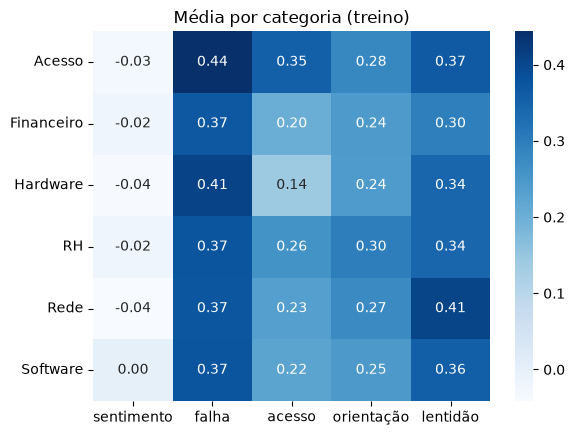

In [3]:
medias = df[df["split"] == "train"].groupby("target_category")[COLUNAS].mean()
medias.columns = ["sentimento", "falha", "acesso", "orientação", "lentidão"]
sns.heatmap(medias, annot=True, fmt=".2f", cmap="Blues").set(title="Média por categoria (treino)", ylabel="")
plt.show()

Lendo o mapa:

- **Acesso** é a coluna mais útil: a média é bem mais alta nos chamados de **Acesso** do que nas outras categorias, e mais baixa em Hardware. O texto desses chamados realmente se parece com pedidos de senha e permissão.
- **Lentidão** é mais alta em **Rede**, o que combina com relatos de rede lenta ou instável.
- **Falha** e **orientação** variam pouco: quase todo chamado relata algum problema, e quase nenhum é uma dúvida de verdade.
- **Sentimento** é praticamente igual em todas as categorias, então contribui pouco.

Nenhuma coluna separa as categorias sozinha. O valor delas está em **somar** informação ao texto, à imagem e aos dados tabulares no classificador final.

---
## Parte 2 — Como as colunas foram geradas

### Visão geral

```text
title + description
        │
        ├──► Modelo de inferência textual (NLI) ──► compara com 3 frases de "tom" ───► sentiment_score
        │
        └──► Modelo de embeddings de frases ──────► compara com 12 frases-exemplo ───► 4 similaridades
```

Quatro regras valem para toda a etapa:

1. **Nenhum modelo é treinado.** As duas redes neurais são pré-treinadas, baixadas do Hugging Face, e usadas só para fazer previsões ("congeladas").
2. **A categoria (`target_category`) nunca é usada.** Isso evita que o PLN "cole" a resposta nas colunas que o classificador vai usar.
3. **Tudo é configurado no YAML** (`src/config/models.yaml`, bloco `modelos.pln`): os modelos, as frases de referência e os limites de tamanho do texto. Para mudar as features, muda-se o YAML, não o código.
4. **Textos repetidos são processados uma vez só.** Como o dataset tem muitas frases iguais, o resultado de cada frase é calculado uma vez e reaproveitado.

Os dois modelos são **multilíngues**, o que é necessário porque os chamados estão em português.

### Como o `sentiment_score` é calculado

O modelo usado é o `MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli`, treinado em **NLI** (*Natural Language Inference*, ou inferência textual). Um modelo de NLI recebe duas frases, um **texto** e uma **hipótese**, e diz se o texto **confirma** a hipótese, se **não tem relação** com ela ou se a **contradiz**.

O truque é usar isso sem treinar nada (*zero-shot*): escrevemos uma hipótese para cada tom possível e perguntamos ao modelo qual delas o chamado confirma mais. As hipóteses estão no YAML:

| Valor | Hipótese |
| --- | --- |
| −1 | "O solicitante expressa insatisfação, frustração ou uma experiência negativa." |
| 0 | "O solicitante apresenta uma informação ou pedido de forma neutra." |
| +1 | "O solicitante expressa satisfação, agradecimento ou uma experiência positiva." |

O cálculo tem três passos:

1. O título e a descrição são juntados em um único texto, e o modelo dá uma nota para o quanto esse texto confirma cada uma das três hipóteses.
2. As três notas são convertidas em **probabilidades que somam 1** (uma operação chamada *softmax*).
3. O sentimento é a **média ponderada** dos valores: `p(negativo) × (−1) + p(neutro) × 0 + p(positivo) × (+1)`.

Exemplo: se o modelo der 20% para negativo, 70% para neutro e 10% para positivo, o sentimento é `0,2 × (−1) + 0,1 × (+1) = −0,10`.

Isso também explica por que os valores ficam perto de zero: a hipótese neutra quase sempre fica com a maior parte da probabilidade, e o negativo e o positivo se anulam em parte.

### Como as quatro similaridades são calculadas

O modelo usado é o `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`, que gera ***embeddings***: ele transforma uma frase em uma lista de **384 números** (um vetor) que representa o **significado** da frase. Ele foi treinado para que frases com sentido parecido tenham vetores parecidos, mesmo que usem palavras diferentes. Por exemplo, "o sistema está lento" e "a aplicação demora para responder" ficam com vetores próximos.

Para cada coluna, o YAML tem **três frases-exemplo** que representam aquela intenção:

| Coluna | Frases-exemplo |
| --- | --- |
| `text_failure_similarity` | "O sistema apresenta um erro e não funciona." · "O equipamento parou de funcionar e preciso de reparo." · "Não consigo realizar minha atividade porque o serviço está indisponível." |
| `text_access_request_similarity` | "Solicito criação de uma conta e liberação de acesso." · "Preciso de permissão para utilizar o sistema." · "Quero redefinir minha senha para acessar minha conta." |
| `text_guidance_similarity` | "Tenho uma dúvida e preciso de orientação para usar o sistema." · "Gostaria de saber como realizar esta operação." · "Solicito informações e instruções sobre o serviço." |
| `text_performance_similarity` | "O sistema está lento e demora muito para responder." · "A aplicação fica travando durante o uso." · "O processamento demora e preciso melhorar o desempenho." |

Essas frases descrevem **tipos de pedido**, não as categorias do alvo: não existe um grupo "RH" ou "Financeiro".

O cálculo tem quatro passos:

1. **Texto → vetor.** O título e a descrição são transformados em vetores **separadamente**. Internamente, o modelo quebra a frase em pedaços (*tokens*), gera um vetor para cada pedaço e tira a **média**; depois o vetor é ajustado para ter tamanho 1 (normalização).
2. **Combinar os dois campos.** Os vetores do título e da descrição são **somados com peso igual** e normalizados de novo. Se um dos campos estiver vazio, o outro é usado sozinho.
3. **Comparar com as frases-exemplo.** As 12 frases-exemplo também viram vetores, e calcula-se a **similaridade de cosseno** entre o chamado e cada uma delas. O cosseno mede o quanto dois vetores apontam para a mesma direção: **1** = mesmo sentido, **0** = sem relação.
4. **Ficar com o maior.** Cada coluna recebe o **maior** dos três cossenos do seu grupo. Basta o chamado se parecer bastante com **uma** das frases-exemplo para o valor ser alto.

### Onde isso está no código

O comando `python -m src.data.pipeline --train-multimodal` (ou `--features`) chega ao PLN por este caminho:

| Passo | Arquivo → função | O que faz |
| --- | --- | --- |
| 1 | `src/models/features_pipeline.py` → `run_features` | Percorre as etapas do YAML. O campo `adapter: semantic_nlp` escolhe a classe `SemanticNLP` |
| 2 | `src/models/language.py` → `SemanticNLP.fit` | Carrega as duas redes e transforma as 12 frases-exemplo em vetores. Apesar do nome `fit`, **não aprende nada** com os chamados |
| 3 | `src/models/language.py` → `SemanticNLP.transform` | Gera as cinco colunas para treino, validação e teste |
| 3a | `language.py` → `probabilities` e `weighted_score` | Sentimento: notas das 3 hipóteses → softmax → média ponderada |
| 3b | `src/models/semantic_text.py` → `SemanticTextEncoder.encode` e `combine_fields` | Similaridades: texto → vetor, e soma de título + descrição |
| 3c | `semantic_text.py` → `intent_similarities` | Cosseno com as frases-exemplo e o maior valor de cada grupo |
| 4 | `features_pipeline.py` → `merge_outputs` | Junta as colunas ao dataset: `sentiment_score` substitui a original e as outras quatro são adicionadas |
| 5 | `language.py` → `SemanticNLP.save` | Salva as redes e as frases-exemplo já convertidas em `models/runs/<execução>/pln/`, para a execução poder ser repetida sem baixar nada |

O coração do cálculo cabe em poucas linhas. Em `weighted_score`, o sentimento é:

```python
probabilidades @ valores            # (p_neg, p_neutro, p_pos) · (−1, 0, +1)
```

E em `intent_similarities`, cada coluna é:

```python
(vetores_chamados @ vetores_exemplos.T).max(axis=1)   # cosseno com cada exemplo, fica o maior
```

O `@` é a multiplicação de matrizes. Como todos os vetores têm tamanho 1, ela calcula exatamente o cosseno.

O resultado final fica no `enriched.parquet` de cada execução, em `reports/runs/<execução>/`.

### Limitações

- **As colunas dependem das frases escolhidas no YAML.** Trocar, tirar ou acrescentar frases-exemplo muda os valores. Essa escolha deve ser avaliada só com treino e validação.
- **As similaridades medem palavras e estrutura, não o assunto.** Frases como "Erro de permissão no Sistema ERP" ficam com alta similaridade de acesso, mesmo estando rotuladas como Software.
- **Os valores não são probabilidades calibradas.** Uma similaridade de 0,5 não significa "50% de chance".
- **O dataset é sintético.** As frases são curtas, montadas por modelos de texto e muito repetidas. Em chamados reais, mais longos e variados, o comportamento pode ser diferente.
- **A utilidade real ainda precisa ser medida.** A forma correta de saber quanto essas colunas ajudam é treinar o classificador final **com e sem elas**, na mesma divisão dos dados (ablação), como pede `docs/analysis/AVALIACAO.md`.